Setting up drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Installing dependencies

In [2]:
pip install onnxruntime-gpu opencv-python numpy scipy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.4/251.4 MB 61.6 MB/s  0:00:04


code:(created from matlab version)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Functions imported successfully.

Loading ultrasound RF data...
Input file variables: ['USDATA']
RF data loaded.
RF shape: (2944, 128, 75)
RF dtype: int16

Loading ultrasound header...
Header variables: ['#refs#', 'USHEADER']
Header loaded.
Transmission angles: [-16.         -15.56756757 -15.13513514 -14.7027027  -14.27027027
 -13.83783784 -13.40540541 -12.97297297 -12.54054054 -12.10810811
 -11.67567568 -11.24324324 -10.81081081 -10.37837838  -9.94594595
  -9.51351351  -9.08108108  -8.64864865  -8.21621622  -7.78378378
  -7.35135135  -6.91891892  -6.48648649  -6.05405405  -5.62162162
  -5.18918919  -4.75675676  -4.32432432  -3.89189189  -3.45945946
  -3.02702703  -2.59459459  -2.16216216  -1.72972973  -1.2972973
  -0.86486486  -0.43243243   0.           0.43243243   0.86486486
   1.2972973    1.72972973   2.16216216   2.59459459   3.02702703
   3.45945946   

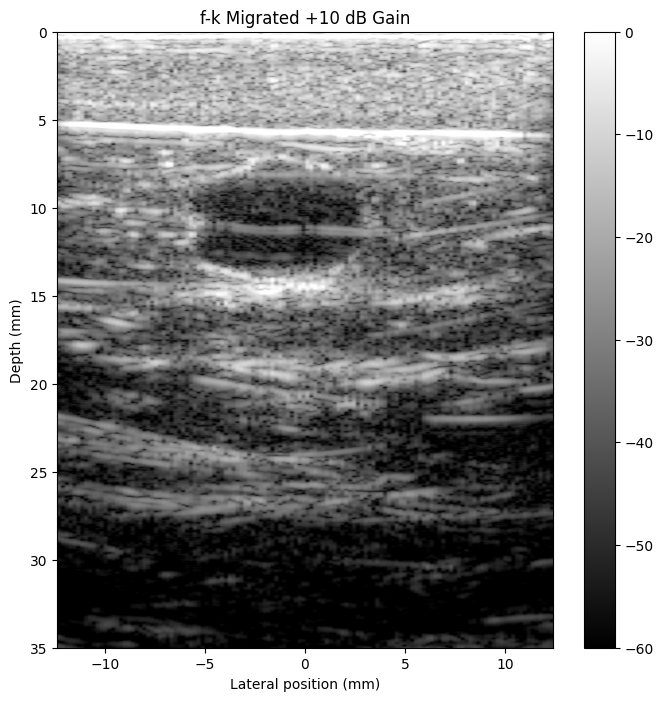


ENHANCEMENT2
Enhancement completed.
Enhanced image shape: (2848, 128)
Enhanced image minimum: -103.161625699869
Enhanced image maximum: -1.3006649475432184

Displaying final enhanced B-mode...


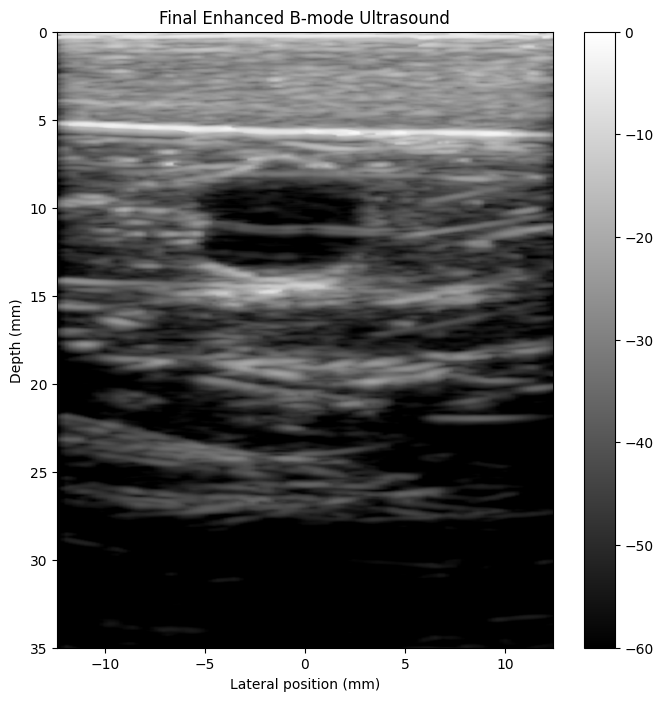


PIPELINE COMPLETED
Preprocessed RF shape: (2848, 128, 75)
FK migrated shape: (2848, 128)
Envelope shape: (2848, 128)
Gain-adjusted shape: (2848, 128)
Final enhanced shape: (2848, 128)

Final image stored in variable: enhanced_img


In [ ]:

# ============================================================
# FINAL ULTRASOUND RECONSTRUCTION PIPELINE
# MATLAB v7.3 -> PYTHON / GOOGLE COLAB
#
# Pipeline:
# Raw RF Data
#   -> Preprocessing
#   -> FK Migration
#   -> Hilbert Envelope
#   -> Normalization
#   -> +10 dB Gain
#   -> Log Compression
#   -> Enhancement2
#   -> Final B-mode
# ============================================================

import os
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import hilbert
from google.colab import drive

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')

# ============================================================
# 2. FILE PATHS
# ============================================================

DATA_PATH = (
    "//content/drive/MyDrive/Dataset/Hypo_lesion/USDATA_20210624112717871.mat"
)

HEADER_PATH = (
    "/content/drive/MyDrive/"
    "USHEADER_20210624112712.mat"
)

# Python functions are already stored in MyDrive
sys.path.append("/content/drive/MyDrive")

# ============================================================
# 3. IMPORT FUNCTIONS
# ============================================================

from preprocessing import preprocessing
from fkmig import fkmig
from enhancement2 import enhancement2

print("Functions imported successfully.")

# ============================================================
# 4. MATLAB v7.3 DATA LOADER
# ============================================================

def matlab_array(dataset):
    """
    Convert an HDF5 dataset into MATLAB array orientation.
    MATLAB v7.3 dimensions are generally reversed in h5py.
    """

    arr = np.array(dataset)

    if arr.ndim > 1:
        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1))
        )

    return arr


# ============================================================
# 5. LOAD RAW RF DATA
# ============================================================

print("\nLoading ultrasound RF data...")

with h5py.File(DATA_PATH, "r") as f:

    print("Input file variables:", list(f.keys()))

    if "USDATA" not in f:
        raise KeyError("USDATA variable not found in input MAT file.")

    sig = matlab_array(f["USDATA"])

sig = np.squeeze(sig)

print("RF data loaded.")
print("RF shape:", sig.shape)
print("RF dtype:", sig.dtype)

# ============================================================
# 6. LOAD ULTRASOUND HEADER
# ============================================================

print("\nLoading ultrasound header...")

with h5py.File(HEADER_PATH, "r") as f:

    print("Header variables:", list(f.keys()))

    if "USHEADER" not in f:
        raise KeyError("USHEADER structure not found in header MAT file.")

    header_group = f["USHEADER"]

    if "xmitAngles" not in header_group:
        raise KeyError("xmitAngles field not found in USHEADER.")

    angle_dataset = header_group["xmitAngles"]

    # Handle MATLAB v7.3 object-reference fields
    if h5py.check_dtype(ref=angle_dataset.dtype) is not None:

        refs = angle_dataset[()].flatten()

        valid_refs = [ref for ref in refs if ref]

        if not valid_refs:
            raise ValueError("No valid xmitAngles reference found.")

        angle_dataset = f[valid_refs[0]]

    tx_angles = matlab_array(angle_dataset).squeeze()

tx_angles = np.asarray(tx_angles, dtype=np.float64).flatten()

USHEADER = {
    "xmitAngles": tx_angles
}

print("Header loaded.")
print("Transmission angles:", tx_angles)
print("Number of angles:", len(tx_angles))

# ============================================================
# 7. RECONSTRUCTION PARAMETERS
# ============================================================

param = {}

param["x"] = np.linspace(-0.0125, 0.0125, 128)
param["y"] = np.linspace(0, 0.0725, 500)

param["fs"] = 31250000
param["c"] = 1540
param["p"] = 0

param["TXangle"] = np.deg2rad(tx_angles)

param["pitch"] = 1.953000000000000e-04

param["passband"] = [0.3, 0.7]
param["ncol"] = 128

# MATLAB param.to = 0
param["t0"] = 0

# ============================================================
# 8. PREPROCESSING
# ============================================================

print("\n========================================")
print("PREPROCESSING")
print("========================================")

sig, param = preprocessing(
    sig,
    USHEADER,
    param
)

print("Preprocessing completed.")
print("Preprocessed shape:", sig.shape)
print("Preprocessed dtype:", sig.dtype)

# ============================================================
# 9. FK MIGRATION
# ============================================================

print("\n========================================")
print("FK MIGRATION")
print("========================================")

migSIG, param = fkmig(sig, param)

print("FK migration completed.")
print("Migrated shape:", migSIG.shape)
print("Migrated dtype:", migSIG.dtype)

# ============================================================
# 10. HILBERT ENVELOPE DETECTION
# ============================================================

print("\n========================================")
print("HILBERT ENVELOPE")
print("========================================")

# MATLAB:
# env = abs(hilbert(migSIG));

env = np.abs(hilbert(migSIG, axis=0))

print("Envelope shape:", env.shape)

# ============================================================
# 11. NORMALIZATION
# ============================================================

print("\n========================================")
print("NORMALIZATION")
print("========================================")

eps_matlab = np.finfo(np.float64).eps

# MATLAB:
# env = env ./ (max(env(:)) + eps);

env = env / (np.max(env) + eps_matlab)

print("Normalized range:")
print("Minimum:", np.min(env))
print("Maximum:", np.max(env))

# ============================================================
# 12. +10 dB GAIN
# ============================================================

print("\n========================================")
print("GAIN")
print("========================================")

# MATLAB:
# gain_dB = 10;
# gain = 10^(gain_dB / 20);
# env_enhanced = env * gain;

gain_dB = 10

gain = 10 ** (gain_dB / 20)

env_enhanced = env * gain

print("Gain:", gain_dB, "dB")
print("Linear gain:", gain)

# ============================================================
# 13. LOG COMPRESSION
# ============================================================

print("\n========================================")
print("LOG COMPRESSION")
print("========================================")

# MATLAB:
# env_dB = 20 * log10(env_enhanced + eps);

env_dB = 20 * np.log10(env_enhanced + eps_matlab)

print("Log-compressed shape:", env_dB.shape)

# ============================================================
# 14. FK MIGRATED IMAGE DISPLAY
# ============================================================

print("\nDisplaying FK migrated image...")

x_mm = np.asarray(param["x"]).squeeze() * 1000
z_mm = np.asarray(param["z"]).squeeze() * 1000

plt.figure(figsize=(8, 8))

plt.imshow(
    env_dB,
    extent=[
        x_mm[0], x_mm[-1],
        z_mm[-1], z_mm[0]
    ],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0,
    origin="upper"
)

plt.ylim(35, 0)
plt.colorbar()
plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")
plt.title("f-k Migrated +10 dB Gain")

plt.show()

# ============================================================
# 15. FOUR-STAGE ENHANCEMENT
# ============================================================

print("\n========================================")
print("ENHANCEMENT2")
print("========================================")

# MATLAB:
# enhanced_img = enhancement2(env_enhanced);

enhanced_img = enhancement2(env_enhanced)

print("Enhancement completed.")
print("Enhanced image shape:", enhanced_img.shape)
print("Enhanced image minimum:", np.min(enhanced_img))
print("Enhanced image maximum:", np.max(enhanced_img))

# ============================================================
# 16. FINAL ENHANCED B-MODE DISPLAY
# ============================================================

print("\nDisplaying final enhanced B-mode...")

plt.figure(figsize=(8, 8))

plt.imshow(
    enhanced_img,
    extent=[
        x_mm[0], x_mm[-1],
        z_mm[-1], z_mm[0]
    ],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0,
    origin="upper"
)

plt.ylim(35, 0)
plt.colorbar()
plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")
plt.title("Final Enhanced B-mode Ultrasound")

plt.show()

# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n========================================")
print("PIPELINE COMPLETED")
print("========================================")

print("Preprocessed RF shape:", sig.shape)
print("FK migrated shape:", migSIG.shape)
print("Envelope shape:", env.shape)
print("Gain-adjusted shape:", env_enhanced.shape)
print("Final enhanced shape:", enhanced_img.shape)

print("\nFinal image stored in variable: enhanced_img")


Intregaton with cnn

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All required files found.
Preprocessing, FK migration and enhancement imported.

========== HEADER LOADING ==========
Header variables: ['#refs#', 'USHEADER']
Header loaded successfully.
Transmission angles: [-16.         -15.56756757 -15.13513514 -14.7027027  -14.27027027
 -13.83783784 -13.40540541 -12.97297297 -12.54054054 -12.10810811
 -11.67567568 -11.24324324 -10.81081081 -10.37837838  -9.94594595
  -9.51351351  -9.08108108  -8.64864865  -8.21621622  -7.78378378
  -7.35135135  -6.91891892  -6.48648649  -6.05405405  -5.62162162
  -5.18918919  -4.75675676  -4.32432432  -3.89189189  -3.45945946
  -3.02702703  -2.59459459  -2.16216216  -1.72972973  -1.2972973
  -0.86486486  -0.43243243   0.           0.43243243   0.86486486
   1.2972973    1.72972973   2.16216216   2.59459459   3.02702703
   3.45945946   3.89189189   4.32432432   4.75675676   5.18918919
   5

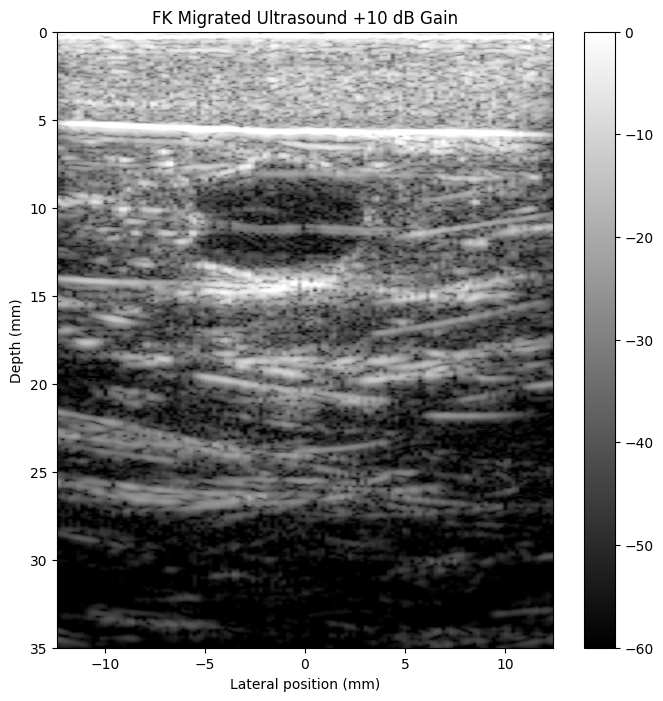


========== IMAGE ENHANCEMENT ==========
Enhancement completed.
Enhanced image dimensions: (2848, 128)
Enhanced image dtype: float32


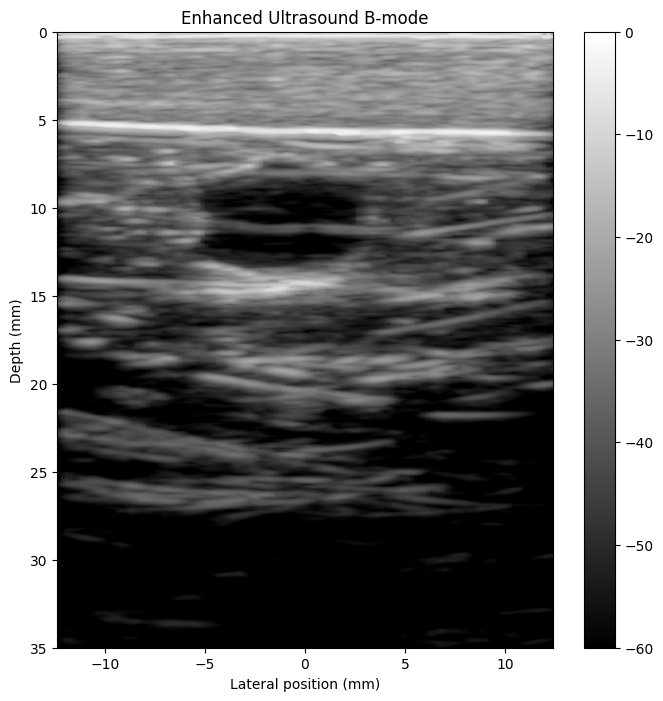


========== CNN INPUT PREPARATION ==========
CNN input prepared.
CNN input shape: (1, 1, 2848, 128)
CNN input dtype: float32

========== CNN CLASSIFICATION ==========
Classification completed.


       RUMC ULTRASOUND CLASSIFICATION       

Predicted Class: Hypo_lesion

Class Confidence Scores:
  No_lesion      : 5.18 %
  Hypo_lesion    : 62.38 %
  Hyper_lesion   : 32.43 %



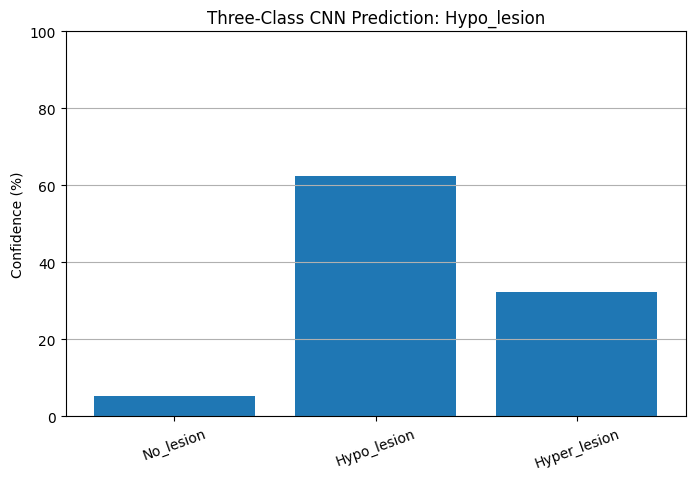


========== PIPELINE COMPLETE ==========
Ultrasound data loading: SUCCESS
Preprocessing: SUCCESS
FK migration: SUCCESS
Envelope detection: SUCCESS
Normalization and gain: SUCCESS
Image enhancement: SUCCESS
ONNX CNN classification: SUCCESS

Final Prediction: Hypo_lesion

Final enhanced image variable: enhanced_img
CNN confidence scores variable: scores



In [ ]:

# ============================================================
# FINAL RUMC ULTRASOUND IMPLEMENTATION
# MATLAB -> PYTHON / GOOGLE COLAB
#
# Pipeline:
# Raw RF Data
#     -> Preprocessing
#     -> FK Migration
#     -> Hilbert Envelope
#     -> Normalization
#     -> +10 dB Gain
#     -> Enhancement
#     -> Three-Class ONNX CNN Classification
#     -> B-mode Display
#
# Classes:
#   1. No_lesion
#   2. Hypo_lesion
#   3. Hyper_lesion
# ============================================================

import os
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt
import onnxruntime as ort

from scipy.signal import hilbert
from google.colab import drive

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')

# ============================================================
# 2. FILE CONFIGURATION
# ============================================================

# Ultrasound input file
DATA_PATH = (
    "/content/drive/MyDrive/Dataset/Hypo_lesion/USDATA_20210624112719205.mat"
)

# Ultrasound header
HEADER_PATH = (
    "/content/drive/MyDrive/"
    "USHEADER_20210624112712.mat"
)

# Converted CNN model
ONNX_PATH = (
    "/content/drive/MyDrive/"
    "RUMC_ThreeClass_CNN.onnx"
)

# Python functions already stored in MyDrive
sys.path.append("/content/drive/MyDrive")

# ============================================================
# 3. CHECK REQUIRED FILES
# ============================================================

for path in [DATA_PATH, HEADER_PATH, ONNX_PATH]:

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("All required files found.")

# ============================================================
# 4. IMPORT PYTHON FUNCTIONS
# ============================================================

from preprocessing import preprocessing
from fkmig import fkmig
from enhancement2 import enhancement2

print("Preprocessing, FK migration and enhancement imported.")

# ============================================================
# 5. MATLAB V7.3 DATA LOADER
# ============================================================

def matlab_array(dataset):

    arr = np.array(dataset)

    if arr.ndim > 1:
        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1))
        )

    return arr


# ============================================================
# 6. LOAD ULTRASOUND HEADER
# ============================================================

print("\n========== HEADER LOADING ==========")

with h5py.File(HEADER_PATH, "r") as f:

    print("Header variables:", list(f.keys()))

    header_group = f["USHEADER"]

    angle_dataset = header_group["xmitAngles"]

    # Handle MATLAB v7.3 object references
    if h5py.check_dtype(ref=angle_dataset.dtype) is not None:

        refs = angle_dataset[()].flatten()

        valid_refs = [ref for ref in refs if ref]

        if not valid_refs:
            raise ValueError(
                "No valid xmitAngles reference found."
            )

        angle_dataset = f[valid_refs[0]]

    tx_angles = matlab_array(angle_dataset).squeeze()

tx_angles = np.asarray(
    tx_angles,
    dtype=np.float64
).flatten()

USHEADER = {
    "xmitAngles": tx_angles
}

print("Header loaded successfully.")
print("Transmission angles:", tx_angles)

# ============================================================
# 7. RECONSTRUCTION PARAMETERS
# ============================================================

param = {}

param["x"] = np.linspace(-0.0125, 0.0125, 128)
param["y"] = np.linspace(0, 0.0725, 500)

param["fs"] = 31250000
param["c"] = 1540
param["p"] = 0

param["TXangle"] = np.deg2rad(tx_angles)

param["pitch"] = 1.953000000000000e-04

param["passband"] = [0.3, 0.7]

param["ncol"] = 128

# MATLAB param.to = 0
param["t0"] = 0

# ============================================================
# 8. LOAD TRAINED ONNX CNN
# ============================================================

print("\n========== CNN MODEL LOADING ==========")

session = ort.InferenceSession(
    ONNX_PATH,
    providers=["CPUExecutionProvider"]
)

input_info = session.get_inputs()[0]
output_info = session.get_outputs()

print("ONNX model loaded successfully.")

print("CNN input name:", input_info.name)
print("CNN input shape:", input_info.shape)
print("CNN input type:", input_info.type)

print("\nCNN output information:")

for output in output_info:
    print(output.name, output.shape, output.type)

# ============================================================
# 9. LOAD RAW ULTRASOUND DATA
# ============================================================

print("\n========== ULTRASOUND DATA LOADING ==========")

with h5py.File(DATA_PATH, "r") as f:

    print("Input variables:", list(f.keys()))

    if "USDATA" not in f:
        raise KeyError(
            "USDATA variable not found in input MAT file."
        )

    sig = matlab_array(f["USDATA"])

sig = np.squeeze(sig)

print("Raw RF data loaded.")
print("Raw RF dimensions:", sig.shape)
print("Raw RF dtype:", sig.dtype)

# ============================================================
# 10. PREPROCESSING
# ============================================================

print("\n========== PREPROCESSING ==========")

# Default: retain all transmission angles.
# Use 1 as fourth argument for zero-degree-only processing.

useZeroDegreeOnly = False

if useZeroDegreeOnly:

    sig, param = preprocessing(
        sig,
        USHEADER,
        param,
        1
    )

else:

    sig, param = preprocessing(
        sig,
        USHEADER,
        param
    )

print("Preprocessing completed.")
print("Preprocessed dimensions:", sig.shape)

# ============================================================
# 11. FK MIGRATION
# ============================================================

print("\n========== FK MIGRATION ==========")

migSIG, param = fkmig(sig, param)

if migSIG.size == 0 or not np.all(np.isfinite(migSIG)):
    raise ValueError("Invalid FK migration output.")

print("FK migration completed.")
print("Migrated dimensions:", migSIG.shape)

# ============================================================
# 12. HILBERT ENVELOPE DETECTION
# ============================================================

print("\n========== ENVELOPE DETECTION ==========")

# MATLAB:
# env = abs(hilbert(migSIG));

env = np.abs(
    hilbert(migSIG, axis=0)
)

if env.size == 0 or not np.all(np.isfinite(env)):
    raise ValueError("Invalid envelope output.")

print("Envelope detection completed.")
print("Envelope dimensions:", env.shape)

# ============================================================
# 13. ENVELOPE NORMALIZATION
# ============================================================

eps_matlab = np.finfo(np.float64).eps

env = env / (
    np.max(env) + eps_matlab
)

print("Envelope normalization completed.")

# ============================================================
# 14. UNIFORM +10 dB GAIN
# ============================================================

gain_dB = 10

gain = 10 ** (gain_dB / 20)

env_enhanced = env * gain

print(f"Applied uniform gain: +{gain_dB:.1f} dB")

# ============================================================
# 15. LOG COMPRESSION FOR DISPLAY
# ============================================================

env_dB = 20 * np.log10(
    env_enhanced + eps_matlab
)

# ============================================================
# 16. VERIFY FK IMAGE COORDINATES
# ============================================================

x_coordinates = np.asarray(param["x"]).squeeze()

if x_coordinates.size != env_dB.shape[1]:
    raise ValueError(
        "Lateral coordinate size does not match migrated image."
    )

if (
    "z" in param
    and np.asarray(param["z"]).size == env_dB.shape[0]
):
    depthCoordinates = np.asarray(param["z"]).squeeze()

elif (
    "y" in param
    and np.asarray(param["y"]).size == env_dB.shape[0]
):
    depthCoordinates = np.asarray(param["y"]).squeeze()

else:
    raise ValueError(
        "No matching depth coordinate for migrated image."
    )

# ============================================================
# 17. DISPLAY FK MIGRATED IMAGE
# ============================================================

print("\nDisplaying FK migrated image...")

plt.figure(figsize=(8, 8))

plt.imshow(
    env_dB,
    extent=[
        x_coordinates[0] * 1000,
        x_coordinates[-1] * 1000,
        depthCoordinates[-1] * 1000,
        depthCoordinates[0] * 1000
    ],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0,
    origin="upper"
)

plt.ylim(35, 0)
plt.colorbar()

plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")

plt.title("FK Migrated Ultrasound +10 dB Gain")

plt.show()

# ============================================================
# 18. FOUR-STAGE IMAGE ENHANCEMENT
# ============================================================

print("\n========== IMAGE ENHANCEMENT ==========")

enhanced_img = enhancement2(env_enhanced)

enhanced_img = np.squeeze(enhanced_img)

if (
    enhanced_img.size == 0
    or enhanced_img.ndim != 2
    or not np.all(np.isfinite(enhanced_img))
):
    raise ValueError("Invalid output from enhancement2.")

# MATLAB:
# enhanced_img = single(enhanced_img);

enhanced_img = enhanced_img.astype(np.float32)

print("Enhancement completed.")
print("Enhanced image dimensions:", enhanced_img.shape)
print("Enhanced image dtype:", enhanced_img.dtype)

# ============================================================
# 19. VERIFY ENHANCED IMAGE COORDINATES
# ============================================================

if enhanced_img.shape[1] != x_coordinates.size:
    raise ValueError(
        "Enhanced image width does not match lateral coordinates."
    )

if (
    "y" in param
    and np.asarray(param["y"]).size == enhanced_img.shape[0]
):
    enhancedDepth = np.asarray(param["y"]).squeeze()

elif (
    "z" in param
    and np.asarray(param["z"]).size == enhanced_img.shape[0]
):
    enhancedDepth = np.asarray(param["z"]).squeeze()

else:
    raise ValueError(
        "No matching depth coordinate for enhanced image."
    )

# ============================================================
# 20. DISPLAY ENHANCED B-MODE IMAGE
# ============================================================

plt.figure(figsize=(8, 8))

plt.imshow(
    enhanced_img,
    extent=[
        x_coordinates[0] * 1000,
        x_coordinates[-1] * 1000,
        enhancedDepth[-1] * 1000,
        enhancedDepth[0] * 1000
    ],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0,
    origin="upper"
)

plt.ylim(35, 0)
plt.colorbar()

plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")

plt.title("Enhanced Ultrasound B-mode")

plt.show()

# ============================================================
# 21. CNN INPUT PREPARATION
# ============================================================

print("\n========== CNN INPUT PREPARATION ==========")

# Original enhanced image is retained.
# No additional normalization, uint8 conversion,
# cropping or resizing is performed.

cnn_img = enhanced_img.astype(np.float32)

model_shape = input_info.shape

# Determine whether the model expects NCHW or NHWC.
# Static dimensions are used when available.

if len(model_shape) != 4:
    raise ValueError(
        f"Expected a 4D CNN input, got: {model_shape}"
    )

# Candidate layouts:
# NCHW = [batch, channel, height, width]
# NHWC = [batch, height, width, channel]

if (
    isinstance(model_shape[1], int)
    and model_shape[1] == 1
):
    cnnInput = cnn_img[np.newaxis, np.newaxis, :, :]

elif (
    isinstance(model_shape[3], int)
    and model_shape[3] == 1
):
    cnnInput = cnn_img[np.newaxis, :, :, np.newaxis]

else:
    raise ValueError(
        "Could not determine CNN channel layout. "
        f"Model input shape: {model_shape}"
    )

# Validate static input dimensions
for actual, expected in zip(cnnInput.shape, model_shape):

    if isinstance(expected, int) and actual != expected:
        raise ValueError(
            f"CNN input mismatch. Model expects {model_shape}, "
            f"but generated {cnnInput.shape}."
        )

cnnInput = np.ascontiguousarray(
    cnnInput,
    dtype=np.float32
)

print("CNN input prepared.")
print("CNN input shape:", cnnInput.shape)
print("CNN input dtype:", cnnInput.dtype)

# ============================================================
# 22. THREE-CLASS ONNX CNN CLASSIFICATION
# ============================================================

print("\n========== CNN CLASSIFICATION ==========")

outputs = session.run(
    None,
    {
        input_info.name: cnnInput
    }
)

# Select the output containing three class scores.
class_output = None

for out in outputs:

    arr = np.asarray(out)

    if arr.size == 3:
        class_output = arr.reshape(-1)
        break

if class_output is None:
    raise ValueError(
        "Could not identify a three-class output. "
        f"Output shapes: {[np.asarray(o).shape for o in outputs]}"
    )

if not np.all(np.isfinite(class_output)):
    raise ValueError("CNN returned non-finite output scores.")

# If outputs are logits, convert to probabilities.
# If already probabilities, retain them.

if (
    np.all(class_output >= 0)
    and np.all(class_output <= 1)
    and np.isclose(np.sum(class_output), 1.0, atol=1e-3)
):
    scores = class_output

else:

    shifted = class_output - np.max(class_output)

    exp_scores = np.exp(shifted)

    scores = exp_scores / np.sum(exp_scores)

# ============================================================
# 23. CLASS LABELS
# ============================================================

# IMPORTANT:
# Confirm this order against the original MATLAB:
# net.Layers(end).Classes
#
# ONNX output order must match this list.

classNames = [
    "No_lesion",
    "Hypo_lesion",
    "Hyper_lesion"
]

predicted_index = int(np.argmax(scores))

resultLabel = classNames[predicted_index]

print("Classification completed.")

# ============================================================
# 24. DISPLAY CLASSIFICATION RESULTS
# ============================================================

print("\n")
print("============================================")
print("       RUMC ULTRASOUND CLASSIFICATION       ")
print("============================================")

print("\nPredicted Class:", resultLabel)

print("\nClass Confidence Scores:")

for name, score in zip(classNames, scores):

    print(
        f"  {name:<15}: {score * 100:.2f} %"
    )

print("\n============================================")

# ============================================================
# 25. DISPLAY CNN PREDICTION GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    classNames,
    scores * 100
)

plt.ylabel("Confidence (%)")
plt.ylim(0, 100)

plt.title(
    f"Three-Class CNN Prediction: {resultLabel}"
)

plt.xticks(rotation=20)

plt.grid(axis="y")

plt.show()

# ============================================================
# 26. FINAL COMPLETION
# ============================================================

print("\n========== PIPELINE COMPLETE ==========")

print("Ultrasound data loading: SUCCESS")
print("Preprocessing: SUCCESS")
print("FK migration: SUCCESS")
print("Envelope detection: SUCCESS")
print("Normalization and gain: SUCCESS")
print("Image enhancement: SUCCESS")
print("ONNX CNN classification: SUCCESS")

print("\nFinal Prediction:", resultLabel)

print("\nFinal enhanced image variable: enhanced_img")
print("CNN confidence scores variable: scores")

print("\n============================================")


Metrics and time calculation

In [4]:
# ============================================================
# FINAL RUMC ULTRASOUND IMPLEMENTATION - METRICS ONLY
# MATLAB -> PYTHON / GOOGLE COLAB
#
# Pipeline:
# Raw RF -> Preprocessing -> FK Migration -> Hilbert Envelope
# -> Normalization -> +10 dB Gain -> Enhancement
# -> Three-Class ONNX CNN Classification
#
# This script suppresses intermediate text and plots and prints
# only the final performance metrics.
# ============================================================

import os
import sys
import time
import warnings
import contextlib

import h5py
import numpy as np
import matplotlib.pyplot as plt
import onnxruntime as ort
from scipy.signal import hilbert
from google.colab import drive

warnings.filterwarnings("ignore")
plt.ioff()

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

# Colab may still display an authorization prompt if Drive needs
# to be mounted or re-authorized.
with open(os.devnull, "w") as _null:
    with contextlib.redirect_stdout(_null):
        with contextlib.redirect_stderr(_null):
            drive.mount("/content/drive")

# ============================================================
# 2. FILE CONFIGURATION
# ============================================================

DATA_PATH = (
    "/content/drive/MyDrive/Dataset/Hypo_lesion/"
    "USDATA_20210624112719205.mat"
)

HEADER_PATH = (
    "/content/drive/MyDrive/"
    "USHEADER_20210624112712.mat"
)

ONNX_PATH = (
    "/content/drive/MyDrive/"
    "RUMC_ThreeClass_CNN.onnx"
)

sys.path.append("/content/drive/MyDrive")

# ============================================================
# 3. CHECK REQUIRED FILES
# ============================================================

for path in (DATA_PATH, HEADER_PATH, ONNX_PATH):
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Required file not found: {path}")

# ============================================================
# 4. IMPORT PROJECT FUNCTIONS
# ============================================================

from preprocessing import preprocessing
from fkmig import fkmig
from enhancement2 import enhancement2

# ============================================================
# 5. MATLAB V7.3 DATA LOADER
# ============================================================

def matlab_array(dataset):
    arr = np.array(dataset)

    if arr.ndim > 1:
        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1))
        )

    return arr

# ============================================================
# 6. LOAD ULTRASOUND HEADER
# ============================================================

with h5py.File(HEADER_PATH, "r") as f:
    header_group = f["USHEADER"]
    angle_dataset = header_group["xmitAngles"]

    # Handle MATLAB v7.3 object references.
    if h5py.check_dtype(ref=angle_dataset.dtype) is not None:
        refs = angle_dataset[()].flatten()
        valid_refs = [ref for ref in refs if ref]

        if not valid_refs:
            raise ValueError("No valid xmitAngles reference found.")

        angle_dataset = f[valid_refs[0]]

    tx_angles = matlab_array(angle_dataset).squeeze()

tx_angles = np.asarray(tx_angles, dtype=np.float64).flatten()

USHEADER = {"xmitAngles": tx_angles}

# ============================================================
# 7. RECONSTRUCTION PARAMETERS
# ============================================================

param = {}

param["x"] = np.linspace(-0.0125, 0.0125, 128)
param["y"] = np.linspace(0, 0.0725, 500)

param["fs"] = 31250000
param["c"] = 1540
param["p"] = 0
param["TXangle"] = np.deg2rad(tx_angles)
param["pitch"] = 1.953000000000000e-04
param["passband"] = [0.3, 0.7]
param["ncol"] = 128
param["t0"] = 0

# ============================================================
# 8. LOAD ONNX CNN
# ============================================================

session = ort.InferenceSession(
    ONNX_PATH,
    providers=["CPUExecutionProvider"]
)

input_info = session.get_inputs()[0]
model_shape = input_info.shape

# ============================================================
# 9. START BENCHMARK AND LOAD RF DATA
# ============================================================

processing_start = time.perf_counter()

with h5py.File(DATA_PATH, "r") as f:
    if "USDATA" not in f:
        raise KeyError("USDATA variable not found in input MAT file.")

    sig = matlab_array(f["USDATA"])

sig = np.squeeze(sig)
raw_rf_size_bytes = sig.nbytes

if sig.size == 0:
    raise ValueError("Loaded RF data is empty.")

# ============================================================
# 10. PREPROCESSING
# ============================================================

# False: retain all transmission angles.
# True: use zero-degree-only processing (fourth argument = 1).
useZeroDegreeOnly = False

if useZeroDegreeOnly:
    sig, param = preprocessing(sig, USHEADER, param, 1)
else:
    sig, param = preprocessing(sig, USHEADER, param)

# ============================================================
# 11. FK MIGRATION
# ============================================================

migSIG, param = fkmig(sig, param)

if migSIG.size == 0 or not np.all(np.isfinite(migSIG)):
    raise ValueError("Invalid FK migration output.")

# ============================================================
# 12. HILBERT ENVELOPE DETECTION
# ============================================================

env = np.abs(hilbert(migSIG, axis=0))

if env.size == 0 or not np.all(np.isfinite(env)):
    raise ValueError("Invalid envelope output.")

# ============================================================
# 13. NORMALIZATION
# ============================================================

eps_matlab = np.finfo(np.float64).eps
env = env / (np.max(env) + eps_matlab)

# ============================================================
# 14. UNIFORM +10 dB GAIN
# ============================================================

gain_dB = 10
gain = 10 ** (gain_dB / 20)
env_enhanced = env * gain

# ============================================================
# 15. LOG COMPRESSION (retained from original pipeline)
# ============================================================

env_dB = 20 * np.log10(env_enhanced + eps_matlab)

# ============================================================
# 16. IMAGE COORDINATES VALIDATION
# ============================================================

x_coordinates = np.asarray(param["x"]).squeeze()

if x_coordinates.size != env_dB.shape[1]:
    raise ValueError(
        "Lateral coordinate size does not match migrated image."
    )

if (
    "z" in param
    and np.asarray(param["z"]).size == env_dB.shape[0]
):
    depthCoordinates = np.asarray(param["z"]).squeeze()
elif (
    "y" in param
    and np.asarray(param["y"]).size == env_dB.shape[0]
):
    depthCoordinates = np.asarray(param["y"]).squeeze()
else:
    raise ValueError(
        "No matching depth coordinate for migrated image."
    )

# ============================================================
# 17. IMAGE ENHANCEMENT
# ============================================================

enhanced_img = np.squeeze(enhancement2(env_enhanced))

if (
    enhanced_img.size == 0
    or enhanced_img.ndim != 2
    or not np.all(np.isfinite(enhanced_img))
):
    raise ValueError("Invalid output from enhancement2.")

enhanced_img = enhanced_img.astype(np.float32)

# ============================================================
# 18. ENHANCED IMAGE COORDINATES VALIDATION
# ============================================================

if enhanced_img.shape[1] != x_coordinates.size:
    raise ValueError(
        "Enhanced image width does not match lateral coordinates."
    )

if (
    "y" in param
    and np.asarray(param["y"]).size == enhanced_img.shape[0]
):
    enhancedDepth = np.asarray(param["y"]).squeeze()
elif (
    "z" in param
    and np.asarray(param["z"]).size == enhanced_img.shape[0]
):
    enhancedDepth = np.asarray(param["z"]).squeeze()
else:
    raise ValueError(
        "No matching depth coordinate for enhanced image."
    )

# ============================================================
# 19. CNN INPUT PREPARATION
# ============================================================

cnn_img = enhanced_img.astype(np.float32)

if len(model_shape) != 4:
    raise ValueError(
        f"Expected a 4D CNN input, got: {model_shape}"
    )

# Determine NCHW or NHWC based on the static channel dimension.
if isinstance(model_shape[1], int) and model_shape[1] == 1:
    cnnInput = cnn_img[np.newaxis, np.newaxis, :, :]
elif isinstance(model_shape[3], int) and model_shape[3] == 1:
    cnnInput = cnn_img[np.newaxis, :, :, np.newaxis]
else:
    raise ValueError(
        "Could not determine CNN channel layout. "
        f"Model input shape: {model_shape}"
    )

for actual, expected in zip(cnnInput.shape, model_shape):
    if isinstance(expected, int) and actual != expected:
        raise ValueError(
            f"CNN input mismatch. Model expects {model_shape}, "
            f"but generated {cnnInput.shape}."
        )

cnnInput = np.ascontiguousarray(cnnInput, dtype=np.float32)

# ============================================================
# 20. THREE-CLASS ONNX CNN CLASSIFICATION
# ============================================================

outputs = session.run(None, {input_info.name: cnnInput})

class_output = None

for out in outputs:
    arr = np.asarray(out)
    if arr.size == 3:
        class_output = arr.reshape(-1)
        break

if class_output is None:
    raise ValueError(
        "Could not identify a three-class output. "
        f"Output shapes: {[np.asarray(o).shape for o in outputs]}"
    )

if not np.all(np.isfinite(class_output)):
    raise ValueError("CNN returned non-finite output scores.")

# Keep probability outputs; apply softmax to logits.
if (
    np.all(class_output >= 0)
    and np.all(class_output <= 1)
    and np.isclose(np.sum(class_output), 1.0, atol=1e-3)
):
    scores = class_output
else:
    shifted = class_output - np.max(class_output)
    exp_scores = np.exp(shifted)
    scores = exp_scores / np.sum(exp_scores)

# ============================================================
# 21. CLASS LABEL
# ============================================================

# Verify this order against the original MATLAB class order
# and the ONNX output class order.
classNames = [
    "No_lesion",
    "Hypo_lesion",
    "Hyper_lesion"
]

predicted_index = int(np.argmax(scores))
resultLabel = classNames[predicted_index]

# ============================================================
# 22. FINAL PERFORMANCE METRICS
# ============================================================

processing_end = time.perf_counter()
processing_latency = processing_end - processing_start

# Data sizes: original loaded RF input and enhanced output.
input_size_bytes = raw_rf_size_bytes
output_size_bytes = enhanced_img.nbytes

input_size_mb = input_size_bytes / (1024 ** 2)
output_size_mb = output_size_bytes / (1024 ** 2)

throughput = 1.0 / processing_latency if processing_latency > 0 else 0.0
input_rate = input_size_mb / processing_latency if processing_latency > 0 else 0.0
output_rate = output_size_mb / processing_latency if processing_latency > 0 else 0.0

# Restore print in case a prior notebook cell suppressed it.
import builtins

print("\n")
print("=======================================================")
print("       FINAL RUMC ULTRASOUND PERFORMANCE METRICS")
print("=======================================================")

print("\n--- Timing ---")
print(f"Processing Latency       : {processing_latency:.6f} sec")
print(f"Total Execution Time     : {processing_latency:.6f} sec")

print("\n--- Latency Statistics ---")
print(f"Mean Latency             : {processing_latency:.6f} sec")
print(f"Minimum Latency          : {processing_latency:.6f} sec")
print(f"Maximum Latency          : {processing_latency:.6f} sec")
print("Latency Jitter            : N/A (one acquisition; repeat for jitter)")

print("\n--- Throughput ---")
print(f"Throughput               : {throughput:.4f} acquisitions/sec")

print("\n--- Effective Data Rate ---")
print(f"Input RF Size            : {input_size_mb:.4f} MB")
print(f"Output Image Size        : {output_size_mb:.4f} MB")
print(f"Effective Input Rate     : {input_rate:.4f} MB/sec")
print(f"Effective Output Rate    : {output_rate:.4f} MB/sec")

print("\n--- Classification ---")
print(f"Predicted Class          : {resultLabel}")

print("=======================================================")

# Results remain available in the notebook:
# enhanced_img, scores, resultLabel, processing_latency



Ultrasound preprocessing completed.
Remaining samples: 2848
Number of channels: 128
Number of transmission angles: 75


       FINAL RUMC ULTRASOUND PERFORMANCE METRICS

--- Timing ---
Processing Latency       : 49.228392 sec
Total Execution Time     : 49.228392 sec

--- Latency Statistics ---
Mean Latency             : 49.228392 sec
Minimum Latency          : 49.228392 sec
Maximum Latency          : 49.228392 sec
Latency Jitter            : N/A (one acquisition; repeat for jitter)

--- Throughput ---
Throughput               : 0.0203 acquisitions/sec

--- Effective Data Rate ---
Input RF Size            : 53.9062 MB
Output Image Size        : 1.3906 MB
Effective Input Rate     : 1.0950 MB/sec
Effective Output Rate    : 0.0282 MB/sec

--- Classification ---
Predicted Class          : Hypo_lesion
